Here's your Post 5 prompt:  
Topic: DBSCAN: finding clusters K-Means misses.   
Area: Machine Learning.   
Type: build.   
Constraints:    
- Max 800 words (about a 4-minute read)
- End with one question for the reader
- Add 3 test cases, including one edge case
- Use a tiny dataset you make up yourself
Saved the prompt as used.

In [201]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [202]:
df = pd.read_csv('Airbnb_data.csv')
df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,19-10-2018,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,21-05-2019,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,05-07-2019,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,19-11-2018,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [203]:
df['neighbourhood_group'].unique()

<StringArray>
['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx']
Length: 5, dtype: str

In [204]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [205]:
df = df.dropna(subset=['last_review', 'reviews_per_month'])

In [206]:
df = df.dropna(subset=['name', 'host_name'])

In [207]:
df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,19-10-2018,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,21-05-2019,0.38,2,355
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,05-07-2019,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,19-11-2018,0.10,1,0
5,5099,Large Cozy 1 BR Apartment In Midtown East,7322,Chris,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,22-06-2019,0.59,1,129
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48782,36425863,Lovely Privet Bedroom with Privet Restroom,83554966,Rusaa,Manhattan,Upper East Side,40.78099,-73.95366,Private room,129,1,1,07-07-2019,1.00,1,147
48790,36427429,No.2 with queen size bed,257683179,H Ai,Queens,Flushing,40.75104,-73.81459,Private room,45,1,1,07-07-2019,1.00,6,339
48799,36438336,Seas The Moment,211644523,Ben,Staten Island,Great Kills,40.54179,-74.14275,Private room,235,1,1,07-07-2019,1.00,1,87
48805,36442252,1B-1B apartment near by Metro,273841667,Blaine,Bronx,Mott Haven,40.80787,-73.92400,Entire home/apt,100,1,2,07-07-2019,2.00,1,40


In [208]:
df.info()

<class 'pandas.DataFrame'>
Index: 38821 entries, 0 to 48852
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              38821 non-null  int64  
 1   name                            38821 non-null  str    
 2   host_id                         38821 non-null  int64  
 3   host_name                       38821 non-null  str    
 4   neighbourhood_group             38821 non-null  str    
 5   neighbourhood                   38821 non-null  str    
 6   latitude                        38821 non-null  float64
 7   longitude                       38821 non-null  float64
 8   room_type                       38821 non-null  str    
 9   price                           38821 non-null  int64  
 10  minimum_nights                  38821 non-null  int64  
 11  number_of_reviews               38821 non-null  int64  
 12  last_review                     38821 non-null  

In [209]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,3.882100e+04,3.882100e+04,38821.000000,38821.000000,38821.000000,38821.000000,38821.000000,38821.000000,38821.000000,38821.000000
mean,1.810081e+07,6.424582e+07,40.728129,-73.951149,142.332526,5.869220,29.290255,1.373229,5.166611,114.886299
std,1.069372e+07,7.589752e+07,0.054991,0.046693,196.994756,17.389026,48.182900,1.680328,26.302954,129.529950
min,2.539000e+03,2.438000e+03,40.506410,-74.244420,0.000000,1.000000,1.000000,0.010000,1.000000,0.000000
25%,8.721444e+06,7.029525e+06,40.688640,-73.982460,69.000000,1.000000,3.000000,0.190000,1.000000,0.000000
50%,1.887286e+07,2.837092e+07,40.721710,-73.954810,101.000000,2.000000,9.000000,0.720000,1.000000,55.000000
75%,2.756746e+07,1.018905e+08,40.762990,-73.935020,170.000000,4.000000,33.000000,2.020000,2.000000,229.000000
max,3.645581e+07,2.738417e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [210]:
df['room_type'].unique()

<StringArray>
['Private room', 'Entire home/apt', 'Shared room']
Length: 3, dtype: str

In [211]:
df['room_type'].value_counts()

room_type
Entire home/apt    20321
Private room       17654
Shared room          846
Name: count, dtype: int64

In [212]:
df['minimum_nights'].min()

np.int64(1)

In [213]:
df['minimum_nights'].max()

np.int64(1250)

In [214]:
df['minimum_nights'].value_counts()

minimum_nights
2      10300
1       9878
3       6840
4       2749
5       2425
       ...  
37         1
105        1
222        1
58         1
210        1
Name: count, Length: 89, dtype: int64

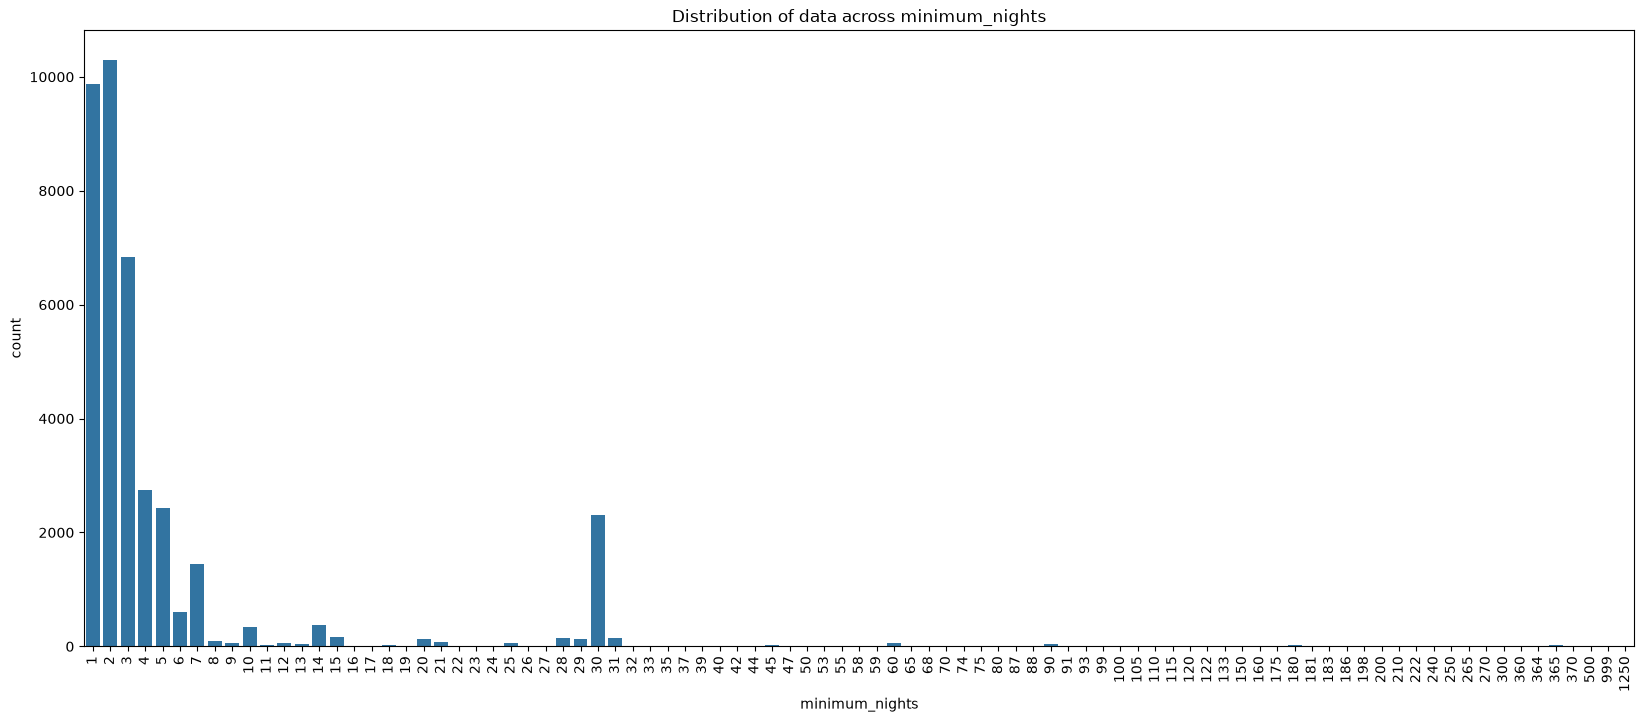

In [215]:
plt.figure(figsize=(20,8))
sns.countplot(data=df, x='minimum_nights')
plt.title('Distribution of data across minimum_nights')
plt.xticks(rotation=90)
plt.show()

In [216]:
# Dropping any bookings that have more than 30 day bookings
df = df[df['minimum_nights'] <= 30]
df.shape

(38382, 16)

In [217]:
unavailable_airbnbs = df[df['availability_365']==0]
unavailable_airbnbs

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,19-11-2018,0.10,1,0
8,5203,Cozy Clean Guest Room - Family Apt,7490,MaryEllen,Manhattan,Upper West Side,40.80178,-73.96723,Private room,79,2,118,21-07-2017,0.99,1,0
20,7801,Sweet and Spacious Brooklyn Loft,21207,Chaya,Brooklyn,Williamsburg,40.71842,-73.95718,Entire home/apt,299,3,9,28-12-2011,0.07,1,0
48,13050,bright and stylish duplex,50846,Jennifer,Brooklyn,Bedford-Stuyvesant,40.68554,-73.94090,Entire home/apt,115,3,11,01-01-2017,0.10,1,0
66,16458,Light-filled 2B duplex in the heart of Park Sl...,64056,Sara,Brooklyn,Park Slope,40.67343,-73.98338,Entire home/apt,225,3,4,24-09-2017,0.16,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46532,35292625,Room-cabin in Hell's kitchen,137191484,Maria,Manhattan,Hell's Kitchen,40.76479,-73.98667,Private room,86,1,1,05-06-2019,0.88,5,0
46583,35329913,Charming Brooklyn Garden apt - historic Macdon...,46724430,Mariana,Brooklyn,Bedford-Stuyvesant,40.68364,-73.92307,Entire home/apt,125,3,1,01-07-2019,1.00,1,0
47175,35615687,Duplex Apartment 3 bedroom 2 bath (6 guest),145082728,Jason & Kelly,Brooklyn,Bedford-Stuyvesant,40.68091,-73.95006,Entire home/apt,350,2,1,30-06-2019,1.00,2,0
47218,35642891,Beautiful room in Bushwick,268138154,Julio,Brooklyn,Bushwick,40.69640,-73.91898,Private room,10,1,2,18-06-2019,2.00,1,0


In [218]:
df['neighbourhood_group'].value_counts()

neighbourhood_group
Manhattan        16371
Brooklyn         16291
Queens            4540
Bronx              867
Staten Island      313
Name: count, dtype: int64

In [219]:
df['neighbourhood'].unique()

<StringArray>
[     'Kensington',         'Midtown',    'Clinton Hill',     'East Harlem',
     'Murray Hill',  'Hell's Kitchen', 'Upper West Side',       'Chinatown',
     'South Slope',    'Williamsburg',
 ...
       'Unionport',      'Mill Basin',          'Hollis',   'Arden Heights',
     'Bull's Head',       'Olinville',       'Rossville',    'Breezy Point',
     'Willowbrook',  'New Dorp Beach']
Length: 218, dtype: str

In [220]:
df = df[df['neighbourhood_group']=='Queens']

In [221]:
freq_map = df['neighbourhood'].value_counts(normalize=True)
df['neighborhood_encoded'] = df['neighbourhood'].map(freq_map)

In [222]:
queens_df = df.set_index('id').drop(columns=['name', 'host_name', 'host_id', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review'])

In [223]:
queens_df.shape

(4540, 9)

In [224]:
queens_df.info()

<class 'pandas.DataFrame'>
Index: 4540 entries, 12937 to 36427429
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   latitude                        4540 non-null   float64
 1   longitude                       4540 non-null   float64
 2   price                           4540 non-null   int64  
 3   minimum_nights                  4540 non-null   int64  
 4   number_of_reviews               4540 non-null   int64  
 5   reviews_per_month               4540 non-null   float64
 6   calculated_host_listings_count  4540 non-null   int64  
 7   availability_365                4540 non-null   int64  
 8   neighborhood_encoded            4540 non-null   float64
dtypes: float64(4), int64(5)
memory usage: 354.7 KB


# K-means Clustering on Queens Airbnb data

A Silhouette analysis is a study used to identify the number of clusters a model needs to divide our data into. We need 

In [225]:
from sklearn.preprocessing import StandardScaler

X = queens_df
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [226]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=11, random_state=101)
kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",11
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",101
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](11, 9)"

In [227]:
# Elbow method to get a rough idea on the number of clusters
wcss_list = []
k_range = range(2, 11)

for k in k_range:
    kmodel = KMeans(n_clusters=k, random_state=101)
    kmodel.fit(X_scaled)
    wcss_list.append(kmodel.inertia_)

for k, wcss in zip(k_range, wcss_list):
    print(f"Clusters (K) = {k} | WCSS = {wcss:.4f}")

Clusters (K) = 2 | WCSS = 33673.8364
Clusters (K) = 3 | WCSS = 30184.0006
Clusters (K) = 4 | WCSS = 25586.8682
Clusters (K) = 5 | WCSS = 23045.3797
Clusters (K) = 6 | WCSS = 21082.5786
Clusters (K) = 7 | WCSS = 18107.9560
Clusters (K) = 8 | WCSS = 16684.6760
Clusters (K) = 9 | WCSS = 15593.0638
Clusters (K) = 10 | WCSS = 14938.3961


In [228]:
from sklearn.metrics import silhouette_score

# silhouette analysis to choose number of clusters
silhouette_list = []
k_range = range(2, 11)

for k in k_range:
    kmodel1 = KMeans(n_clusters=k, random_state=101)
    cluster_labels = kmodel1.fit_predict(X_scaled)
    silhouette_list.append(silhouette_score(X_scaled, cluster_labels))
    
for k, sil_coeff in zip(k_range, silhouette_list):
    print(f"Clusters (K) = {k} | silhouette_score = {sil_coeff:.4f}")

Clusters (K) = 2 | silhouette_score = 0.2098
Clusters (K) = 3 | silhouette_score = 0.2164
Clusters (K) = 4 | silhouette_score = 0.2353
Clusters (K) = 5 | silhouette_score = 0.2120
Clusters (K) = 6 | silhouette_score = 0.1933
Clusters (K) = 7 | silhouette_score = 0.2109
Clusters (K) = 8 | silhouette_score = 0.2175
Clusters (K) = 9 | silhouette_score = 0.2308
Clusters (K) = 10 | silhouette_score = 0.2220


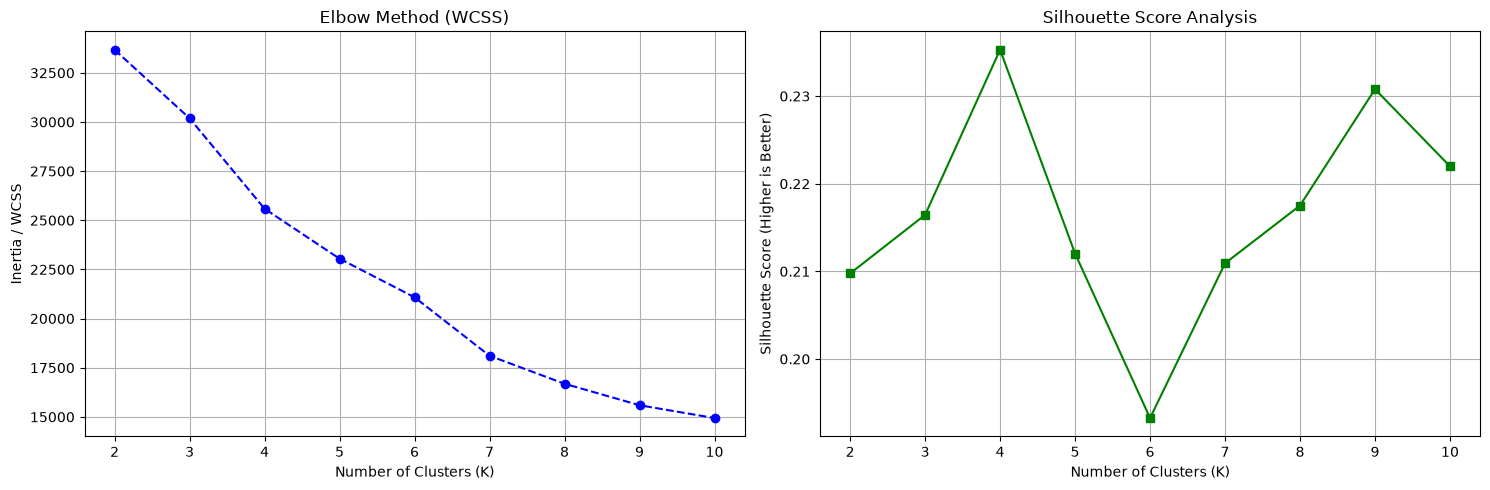

In [229]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: The Elbow Method (Look for the bend/elbow)
ax1.plot(k_range, wcss_list, marker='o', linestyle='--', color='b')
ax1.set_title('Elbow Method (WCSS)')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia / WCSS')
ax1.set_xticks(list(k_range))
ax1.grid(True)

# Plot 2: The Silhouette Score (Look for the highest peak)
ax2.plot(k_range, silhouette_list, marker='s', linestyle='-', color='g')
ax2.set_title('Silhouette Score Analysis')
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Silhouette Score (Higher is Better)')
ax2.set_xticks(list(k_range))
ax2.grid(True)

plt.tight_layout()
plt.show()

In [235]:
# final kmeans model with k=4

model = KMeans(n_clusters=4, n_init=20, random_state=101)
model.fit(X_scaled)

queens_df['kmeans_clusters'] = model.predict(X_scaled)

In [236]:
queens_df.head(10)

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighborhood_encoded,kmeans_clusters
id,,,,,,,,,,
12937,40.74771,-73.94740,130,3,248,2.25,1,215,0.090969,3
18198,40.75038,-73.90334,70,30,25,0.22,1,324,0.037004,1
32363,40.74028,-73.83168,140,2,1,0.01,1,1,0.079956,0
39593,40.74559,-73.92313,79,30,28,0.26,1,126,0.063656,1
45910,40.70382,-73.89797,350,8,10,0.11,5,365,0.066300,0
51850,40.67252,-73.76597,55,2,52,0.49,2,365,0.042291,2
53469,40.71722,-73.87856,98,30,33,0.31,5,240,0.006167,1
53470,40.70234,-73.89816,140,7,6,0.06,5,365,0.066300,0
53477,40.71546,-73.87854,265,7,38,0.38,5,365,0.006167,2


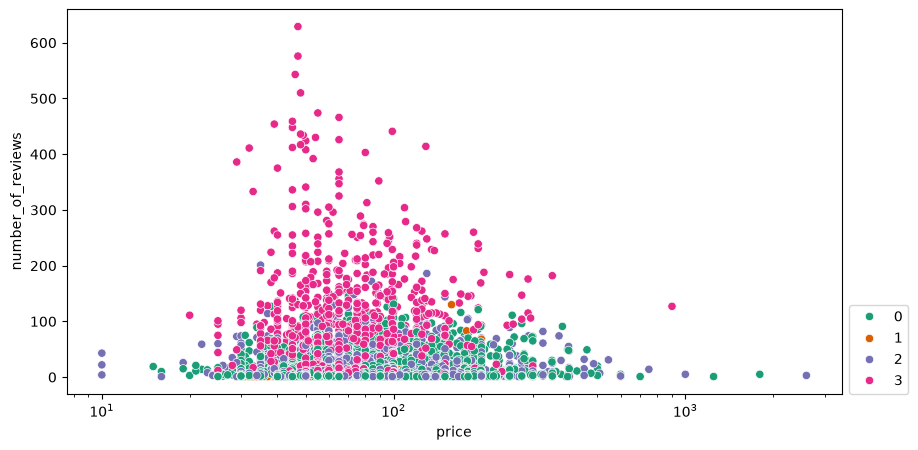

In [239]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=queens_df, x='price', y='number_of_reviews', hue='kmeans_clusters', palette='Dark2')
plt.xscale('log')
plt.legend(loc=(1.01,0))

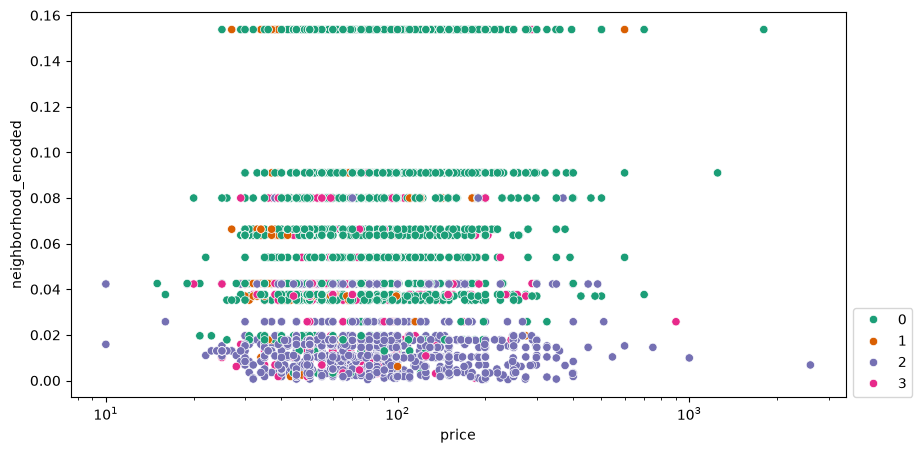

In [241]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=queens_df, x='price', y='neighborhood_encoded', hue='kmeans_clusters', palette='Dark2')
plt.xscale('log')
plt.legend(loc=(1.01,0))

In [ ]:
queens_clusters = queens_df.groupby('kmeans_clusters').median()
queens_clusters

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighborhood_encoded
kmeans_clusters,,,,,,,,,
0,40.75478,-73.91183,75.0,2.0,10.0,0.91,1.0,66.0,0.066300
1,40.74361,-73.90334,48.0,30.0,3.0,0.31,7.0,231.0,0.063656
2,40.69417,-73.80446,70.0,2.0,14.0,1.40,2.0,179.0,0.014537
3,40.74624,-73.87344,65.0,1.0,111.0,4.95,2.0,180.0,0.037665


In [257]:
queens_df['kmeans_clusters'].value_counts().sort_index()

kmeans_clusters
0    2563
1     219
2    1211
3     547
Name: count, dtype: int64

<Axes: xlabel='kmeans_clusters'>

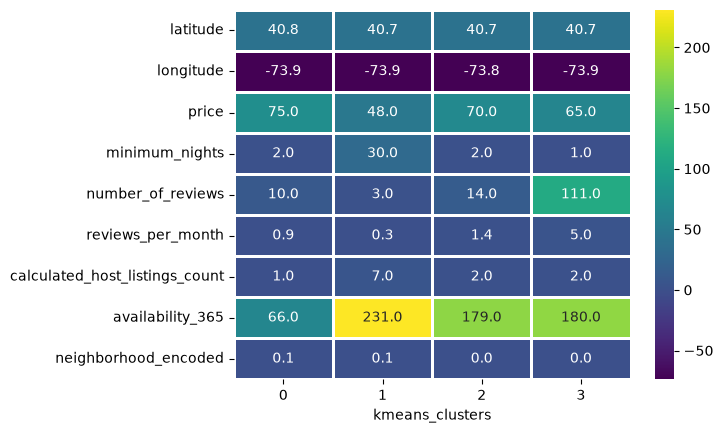

In [251]:
sns.heatmap(queens_clusters.T, annot=True, fmt='.1f', cmap='viridis', linecolor='white', linewidth='1')

In [258]:
pd.crosstab(queens_df['kmeans_clusters'], df.set_index('id')['room_type'])

room_type,Entire home/apt,Private room,Shared room
kmeans_clusters,,,
0,954,1527,82
1,72,139,8
2,503,656,52
3,204,336,7


### K-Means observations (Queens, k = 4)

**Feature by feature**
1. **Price:** cluster 1 has the lowest median price (~$48); clusters 0, 2 and 3 sit at ~$65–75, with cluster 0 the highest (~$75).
2. **Minimum nights:** cluster 1 holds the 30-night listings (median 30); the other clusters need only 1–2 nights.
3. **Availability:** cluster 0 is the least available (median 66 days, open ~18% of the year); cluster 1 is the most available (231 days); clusters 2 and 3 sit around 180 days.
4. **Reviews:** cluster 3 is the highly reviewed group (~111 reviews, ~5 per month); the other clusters have only 3–14 reviews in total and 0.3–1.4 per month.
5. **Hosts:** cluster 1's hosts run ~7 listings each, against 1–2 in the other clusters.
6. **Location:** median latitude and longitude barely change across clusters, so location isn't what separates them.
7. **Room type** (not used for clustering, checked afterwards): every cluster mixes room types. Private rooms outnumber entire homes in all four clusters, and shared rooms are a small share (1–4%) everywhere.

**Cluster profiles**
- **Cluster 0, low-activity listings (2,563, 56%):** least available and few reviews, which suggests calendars blocked by hosts or occasional hosting rather than heavy booking. More than half of Queens listings look like this.
- **Cluster 1, monthly lets (219, 5%):** 30-night minimums, the lowest prices, the highest availability and multi-listing hosts. This may suggest professional hosts offering mostly private rooms for monthly stays, with fewer takers.
- **Cluster 2, open but rarely booked (1,211, 27%):** available about half the year, but with few reviews (~14), so these listings appear to be booked less often.
- **Cluster 3, active and popular (547, 12%):** available about half the year, with by far the most reviews (~111, ~5 per month) at reasonable prices. These look like the busiest listings.

# DBSCAN Clustering on Queens Airbnb data

Note to remember:  
 Unlike K-means, DBSCAN does not require specifying the number of clusters in advance and can identify outliers as noise points.  

This implementation has a worst case memory complexity, which can occur when the eps param is large and min_samples is low, while the original DBSCAN only uses linear memory.

In [259]:
from sklearn.neighbors import NearestNeighbors

# rule of thumb - use no_of_features * 2 for min_samples
min_samples = 2 * X_scaled.shape[1]
neigh = NearestNeighbors(n_neighbors=min_samples)
neigh.fit(X_scaled)
dist, idx = neigh.kneighbors(X_scaled)
print(dist)

[[0.         0.64774575 1.37905777 ... 1.92858129 1.92952231 1.94027003]
 [0.         0.61821977 0.65005062 ... 1.23077416 1.33896888 1.34671518]
 [0.         0.48726093 0.69150651 ... 1.05239556 1.06269624 1.06456901]
 ...
 [0.         0.47362003 0.52439383 ... 0.87365095 0.88589675 0.88810609]
 [0.         0.58426805 0.64471458 ... 0.87143132 0.87934086 0.89551118]
 [0.         0.36314965 0.50167521 ... 0.73776486 0.75174441 0.75785202]]


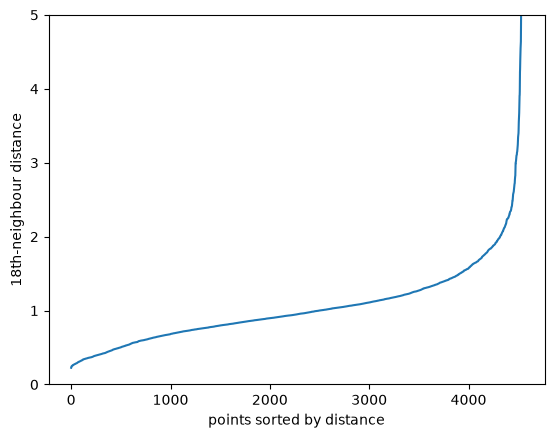

In [265]:
last_col_dist = dist[:,-1]
last_col_dist = np.sort(last_col_dist)
plt.plot(last_col_dist)
plt.xlabel('points sorted by distance')
plt.ylabel('18th-neighbour distance')
plt.ylim(0, 5)
plt.show()

In [268]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps = 2, min_samples=18) 
dbscan.fit(X_scaled)

queens_df['dbscan_clusters'] = dbscan.labels_
queens_df['dbscan_clusters'].value_counts()

dbscan_clusters
 0    4430
-1      75
 1      35
Name: count, dtype: int64

In [269]:
queens_dbscan_clusters = queens_df.groupby('dbscan_clusters').median()
queens_dbscan_clusters

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighborhood_encoded,kmeans_clusters
dbscan_clusters,,,,,,,,,,
-1,40.689680,-73.812450,65.0,1.0,132.0,5.37,3.0,226.0,0.037665,3.0
0,40.745095,-73.891675,75.0,2.0,14.0,1.23,1.0,116.0,0.053965,0.0
1,40.741650,-73.901550,39.0,30.0,1.0,0.43,103.0,239.0,0.037004,1.0


<Axes: xlabel='dbscan_clusters'>

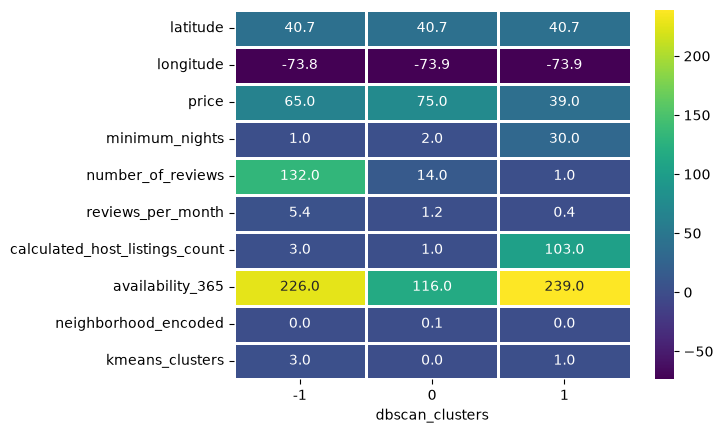

In [270]:
sns.heatmap(queens_dbscan_clusters.T, annot=True, fmt='.1f', cmap='viridis', linecolor='white', linewidth='1')

In [271]:
pd.crosstab(queens_df['dbscan_clusters'], df.set_index('id')['room_type'])

room_type,Entire home/apt,Private room,Shared room
dbscan_clusters,,,
-1,23,48,4
0,1710,2575,145
1,0,35,0


In [272]:
comparison = pd.concat(
    [queens_clusters, queens_dbscan_clusters.drop(columns='kmeans_clusters')],
    keys=['KMeans', 'DBSCAN']
).T
comparison

KMeans                                      \
                                       0           1           2           3   
latitude                        40.75478   40.743610   40.694170   40.746240   
longitude                      -73.91183  -73.903340  -73.804460  -73.873440   
price                           75.00000   48.000000   70.000000   65.000000   
minimum_nights                   2.00000   30.000000    2.000000    1.000000   
number_of_reviews               10.00000    3.000000   14.000000  111.000000   
reviews_per_month                0.91000    0.310000    1.400000    4.950000   
calculated_host_listings_count   1.00000    7.000000    2.000000    2.000000   
availability_365                66.00000  231.000000  179.000000  180.000000   
neighborhood_encoded             0.06630    0.063656    0.014537    0.037665   

                                    DBSCAN                          
                                        -1           0           1  
latitude                         40.689680   40.745095   40.741650  
longitude                       -73.812450  -73.891675  -73.901550  
price                            65.000000   75.000000   39.000000  
minimum_nights                    1.000000    2.000000   30.000000  
number_of_reviews               132.000000   14.000000    1.000000  
reviews_per_month                 5.370000    1.230000    0.430000  
calculated_host_listings_count    3.000000    1.000000  103.000000  
availability_365                226.000000  116.000000  239.000000  
neighborhood_encoded              0.037665    0.053965    0.037004

### K-Means vs DBSCAN: observations
1. **Shape of the data:** K-Means had to split Queens into 4 clusters and assign every listing to one, because it has no notion of noise. DBSCAN found only **2 clusters plus noise**: one dense cluster holding **97.6%** of listings, a tiny cluster of **0.8%** (35 listings), and **1.7%** noise (75 listings).
2. **A hidden niche:** DBSCAN's tiny cluster is very specific: **all 35 are private rooms**, with a 30-night minimum, the lowest median price (~$39), the highest availability (239 days), almost no reviews (median 1) and hosts running **~103 listings each**, which suggests one or a few large operators. K-Means had found a related group (cluster 1, 219 listings, ~7 listings per host), but diluted with mixed room types and smaller hosts.
3. **Popular listings are the outliers:** the noise points have the most reviews (median 132 per listing, ~5.4 per month). They resemble K-Means cluster 3, but DBSCAN treats them as rare, scattered listings rather than a group of their own.
4. **The typical Queens listing:** DB0's hosts usually run a single listing (median 1), with ~14 reviews and a mix of private rooms (2,575), entire homes (1,710) and shared rooms (145).
